<a href="https://colab.research.google.com/github/ericksbr/grouper/blob/main/grouper.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# About Grouper

Grouper is a simple tool that groups **similar comments** in rulemaking submissions based on **word overlap** (not topic). It was designed to work with comments submitted to the Federal Register, but should work with any set of comments in a spreadsheet format.

## What it does
It reads a file of comments (CSV, Excel, or Parquet), groups similar ones together based on text similarity, and labels each comment as:
- **Ungrouped** — no other comment is similar enough (group size = 1)
- **Grouped - Identical** — exactly matches another comment after normalization
- **Grouped - Highly similar** — best match in group has Jaccard ≥ 0.90
- **Grouped - Moderately similar** — best match in group has Jaccard in (0.50, 0.90)

Note: Similarity is based on **wording overlap** (split into 5-word "shingles"), not semantic topic similarity. Two comments discussing the same topic may not group together if they use very different words.

## Groups and families
Each group is anchored on one representative comment, and every member is at least 50% similar to it. Groups whose representatives are at least 30% similar are linked into **families**, which can reveal coordinated campaigns that use several related templates.

## How to use
1. Collapse the "Setup" section. Click the play icon next to "1 cell hidden" to load the required packages.
2. Collapse the "Function Definitions" section. Click the play icon next to "18 cells hidden" to define all the actions this pipeline completes. Advanced users can review the functions.
3. Click play in the Upload File section. Select your comment file (CSV, Excel, or Parquet). Click play in the next cell to confirm the Column and ID (optional). If you need to change these, you can do so in the next cell.
4. Collapse "Pipeline Execution" and click play to run the grouping pipeline. Once running, you can expand and scroll to see progress at each stage.
5. Click play under the Interactive Explorer to browse groups of similar documents.
6. Download your file with new columns added for grouping analysis.

## Key concept
Jaccard similarity measures the fraction of shared 5-word chunks between two comments (0 = no overlap, 1 = identical text).

# Setup

In [1]:
# Install dependencies
import subprocess
import sys

packages = ['pandas', 'numpy', 'scipy', 'scikit-learn', 'openpyxl', 'pyarrow', 'nltk', 'matplotlib', 'tqdm', 'datasketch>=2.0.0,<3', 'psutil']
for package in packages:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

# Imports
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm
from collections import Counter
from difflib import SequenceMatcher
import unicodedata
import re
import time
import gc
import datasketch
from datasketch import MinHash, MinHashLSH
assert tuple(int(p) for p in datasketch.__version__.split('.')[:2]) >= (2, 0), \
    f'datasketch 2.x required, found {datasketch.__version__}'
from ipywidgets import Dropdown, Output, IntText, VBox, HBox, HTML
from IPython.display import display, clear_output
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Download NLTK data
import nltk
try:
    nltk.data.find('tokenizers/punkt_tab')
except LookupError:
    nltk.download('punkt_tab', quiet=True)

# Google Colab file upload
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"✓ Setup complete ({'Google Colab' if IN_COLAB else 'Local Jupyter'})")

✓ Setup complete (Google Colab)


# Upload Your File
Choose the file with comments from your computer.

## Upload helper function

In [2]:
# Function: Load CSV, XLSX, or Parquet file
def load_file(filepath):
    """Load CSV/XLSX/Parquet file as DataFrame."""
    ext = Path(filepath).suffix.lower()
    if ext == '.csv':
        return pd.read_csv(filepath, dtype=str, keep_default_na=False)
    elif ext in ['.xlsx', '.xls']:
        return pd.read_excel(filepath, dtype=str, keep_default_na=False)
    elif ext == '.parquet':
        return pd.read_parquet(filepath).astype(str)
    else:
        raise ValueError(f"Unsupported file type: {ext}")

# Function: Detect which column has comments
def detect_comment_column(df):
    """Auto-detect comment column (longest text on average)."""
    return max(df.columns, key=lambda c: df[c].astype(str).str.len().mean())

# Function: Detect which column has a commenter id
def detect_id_column(df):
    """Auto-detect ID column: any column with 'id' as a word in its name (e.g. 'commenter_id', 'Document ID', 'documentId')."""
    def name_tokens(name):
        spaced = re.sub(r'([a-z0-9])([A-Z])', r'\1 \2', str(name))  # split camelCase
        return [t for t in re.split(r'[^a-z0-9]+', spaced.lower()) if t]

    candidates = []
    for col in df.columns:
        tokens = name_tokens(col)
        if 'id' in tokens or 'ids' in tokens or 'tracking' in tokens:
            candidates.append(col)
    if not candidates:
        return None

    # Prefer commenter-style names, then document/tracking, then plain 'id'
    priority = ['commenter', 'comment', 'document', 'tracking', 'id']
    def rank(col):
        tokens = name_tokens(col)
        return min((priority.index(t) for t in tokens if t in priority), default=len(priority))
    return min(candidates, key=rank)

## Load file

In [3]:
# Run widget to find and load your data
if IN_COLAB:
    print("Click 'Choose Files' to upload your CSV/XLSX/Parquet file:")
    uploaded = files.upload()
    filepath = list(uploaded.keys())[0]
else:
    filepath = input("Enter path to your file (CSV/XLSX/Parquet): ")

print(f"File: {filepath}")

t_load = time.perf_counter()
df = load_file(filepath)
load_seconds = time.perf_counter() - t_load
print(f"Loaded {len(df):,} rows; {len(df.columns)} columns")

Click 'Choose Files' to upload your CSV/XLSX/Parquet file:


Saving noaa_narw_2026.csv to noaa_narw_2026.csv
File: noaa_narw_2026.csv
Loaded 29,798 rows; 60 columns


## Confirm Columns
Check to make sure the column with comments was correctly identified. If you have a commenter identification row, check this as well.

In [4]:
comment_col = detect_comment_column(df)
id_col = detect_id_column(df)

print(f"Comment column: {comment_col}")
print(f"ID column: {id_col or '(row index)'}")

Comment column: Comment
ID column: Comment on Document ID


## Override columns (optional)
If you need to change the comment or ID column, do so here.

In [5]:
comment_dropdown = Dropdown(
    options=df.columns.tolist(),
    value=comment_col,
    description='Comment Column:',
    layout={'width': '500px'}
)

id_dropdown = Dropdown(
    options=['(none)'] + df.columns.tolist(),
    value=id_col if id_col else '(none)',
    description='ID Column:',
    layout={'width': '500px'}
)

output = Output()

def on_comment_change(change):
    global comment_col
    comment_col = change['new']
    update_display()

def on_id_change(change):
    global id_col
    id_col = None if change['new'] == '(none)' else change['new']
    update_display()

def update_display():
    with output:
        output.clear_output()
        sample = df[comment_col].fillna("").astype(str).iloc[0]
        print(f"âœ“ Comment column: {comment_col}")
        print(f"âœ“ ID column: {id_col or '(row index)'}")
        print(f"\nSample ({len(sample)} chars):")
        print(f"{sample[:300]}...")

comment_dropdown.observe(on_comment_change, names='value')
id_dropdown.observe(on_id_change, names='value')

display(VBox([
    HTML("<h3>Confirm Column Selection</h3>"),
    HTML("<p>Update if auto-detection is wrong:</p>"),
    comment_dropdown,
    id_dropdown,
    output
]))

update_display()

# Pipeline Execution
Run the duplicate detector by clicking play. Look at the subsections to understand progress along the way.

## Prepare Data

In [7]:
texts = df[comment_col].fillna("").astype(str).values
n_docs = len(texts)

print(f"{n_docs:,} documents")
print(f"  - Min length: {min((len(t) for t in texts), default=0)} chars")
print(f"  - Max length: {max((len(t) for t in texts), default=0):,} chars")
print(f"  - Mean length: {np.mean([len(t) for t in texts]):.0f} chars")

from datetime import datetime

run_started_at = datetime.now()
t_start = time.perf_counter()
t_stage = t_start
run_stages = {}

def mark_stage(name):
    """Record seconds since the previous stage mark under this name."""
    global t_stage
    now = time.perf_counter()
    run_stages[name] = round(now - t_stage, 3)
    t_stage = now

29,798 documents
  - Min length: 0 chars
  - Max length: 5,000 chars
  - Mean length: 1805 chars


## Exact Match (Raw Text)

Finds comments that are identical to each other.

In [8]:
# Function: Exact match on raw text
def exact_match_raw(texts):
    """Exact match on raw text."""
    df_raw = pd.DataFrame({'text': texts})
    exact_grp_raw = df_raw.groupby('text', sort=False).ngroup() + 1
    is_first_seen_raw = ~df_raw.duplicated('text', keep='first').values
    return exact_grp_raw.values, is_first_seen_raw

In [9]:
exact_grp_raw, is_first_seen_raw = exact_match_raw(texts)
exact_raw_count = (~is_first_seen_raw).sum()

print(f"Identical (raw text): {exact_raw_count:,} ({100*exact_raw_count/n_docs:.1f}%)")
print(f"  Distinct texts: {exact_grp_raw.max():,}")

Identical (raw text): 19,270 (64.7%)
  Distinct texts: 10,528


## Exact Match (Normalized Text)

Find comments that say the same thing, even if they differ slightly in capitalization, punctuation, or spacing. For example, 'I oppose this!' and 'i OPPOSE this' would be treated as different above (raw text) but identical here.

In [10]:
# Function: Normalize text
def normalize_text(text: str) -> str:
    """Normalize text: NFKC, lowercase, NLTK tokenize, alphanumeric filter."""
    text = unicodedata.normalize('NFKC', text)
    text = text.lower()
    tokens = nltk.word_tokenize(text)
    tokens = [t for t in tokens if any(c.isalnum() for c in t)]
    text = ' '.join(tokens)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Function: Exact match on normalized text
def exact_match_normalized(texts, is_first_seen_raw):
    """Exact match on normalized text (efficient: normalize first-seen-raw only)."""
    normalized_texts = np.empty(len(texts), dtype=object)
    raw_to_norm = {}

    # Normalize only first-seen-raw
    for idx in tqdm(np.where(is_first_seen_raw)[0], desc='Normalizing', unit='doc'):
        raw_text = texts[idx]
        norm_text = normalize_text(raw_text)
        normalized_texts[idx] = norm_text
        raw_to_norm[raw_text] = norm_text

    # Propagate to exact raw-text duplicates
    for idx in np.where(~is_first_seen_raw)[0]:
        raw_text = texts[idx]
        normalized_texts[idx] = raw_to_norm.get(raw_text, "")

    # Group on normalized text
    df_norm = pd.DataFrame({'text_normalized': normalized_texts})
    exact_grp_normalized = df_norm.groupby('text_normalized', sort=False).ngroup() + 1
    is_first_seen_normalized = ~df_norm.duplicated('text_normalized', keep='first').values

    return normalized_texts, exact_grp_normalized.values, is_first_seen_normalized

In [11]:
normalized_texts, exact_grp_normalized, is_first_seen_normalized = exact_match_normalized(texts, is_first_seen_raw)
exact_norm_count = (~is_first_seen_normalized).sum()

print(f"Identical (normalized text): {exact_norm_count:,} ({100*exact_norm_count/n_docs:.1f}%)")
print(f"Distinct normalized texts: {exact_grp_normalized.max():,}")
mark_stage('exact_dedupe')


Normalizing: 100%|██████████| 10528/10528 [00:14<00:00, 738.36doc/s]


Identical (normalized text): 19,449 (65.3%)
Distinct normalized texts: 10,349


## Shingles & MinHash

Splits each comment into overlapping 5-word chunks (called shingles), then creates a quick, stable mathematical fingerprint (MinHash) from those chunks so it can rapidly find which comments are similar.

In [12]:
# Function: Build a matrix of shingles (n-word segments from document)
def build_shingle_matrix(texts, k=5):
    """Build sparse shingle matrix (docs — shingles)."""
    all_shingles_set = set()
    doc_shingles = []

    for text in texts:
        words = text.split()
        if len(words) >= k:
            shingles = {' '.join(words[i:i+k]) for i in range(len(words) - k + 1)}
        else:
            shingles = {text}
        doc_shingles.append(shingles)
        all_shingles_set.update(shingles)

    shingle_list = sorted(list(all_shingles_set))
    shingle_to_idx = {s: i for i, s in enumerate(shingle_list)}

    rows, cols, data = [], [], []
    for doc_idx, shingles in enumerate(doc_shingles):
        for shingle in shingles:
            rows.append(doc_idx)
            cols.append(shingle_to_idx[shingle])
            data.append(1)

    X = csr_matrix((data, (rows, cols)), shape=(len(doc_shingles), len(shingle_list)), dtype=np.uint8)
    return X

# Function: Compute MinHash signatures (datasketch, affine32 scheme)
def _identity(x):
    """Shingle ids are already integers below 2**32, so they serve as hash values."""
    return x

def minhash_signatures(X, num_perm=256, seed=42):
    """MinHash signatures via datasketch. Each doc's shingle ids are fed in as hash inputs."""
    n_docs = X.shape[0]
    assert X.shape[1] < 2**32, 'Too many shingles for 32-bit hash inputs'
    assert np.all(np.diff(X.indptr) > 0), 'Every doc needs at least one shingle'

    sig = np.empty((n_docs, num_perm), dtype=np.uint32)
    docs = (X.indices[X.indptr[d]:X.indptr[d + 1]].tolist() for d in range(n_docs))
    mhs = MinHash.generator(docs, num_perm=num_perm, seed=seed, scheme='affine32', hashfunc=_identity)
    for d, mh in enumerate(tqdm(mhs, total=n_docs, desc='MinHash', unit='doc')):
        sig[d] = mh.hashvalues
    return sig


In [13]:
fs_pos = np.where(is_first_seen_normalized)[0]
fs_texts = normalized_texts[fs_pos]
n_fs = len(fs_pos)

print(f"First-seen (normalized): {n_fs:,}")

X = build_shingle_matrix(fs_texts)
print(f"Shingle matrix: {X.shape[0]} docs; {X.shape[1]:,} shingles")

sig = minhash_signatures(X, num_perm=256)
print(f"\nSignatures: {sig.shape}")
mark_stage('minhash')


First-seen (normalized): 10,349
Shingle matrix: 10349 docs; 231,837 shingles


MinHash: 100%|██████████| 10349/10349 [00:01<00:00, 5194.86doc/s]


Signatures: (10349, 256)


## LSH & Jaccard Verification

Organizes the fingerprints from above into groups (LSH bands) so similar comments end up together, then verifies which comments in each group actually are similar by counting how many 5-word chunks they share, keeping only pairs that share at least 50%.

In [14]:
def choose_lsh_params(num_perm, min_threshold, target_recall):
    """Largest rows-per-band r (fewest junk candidates) whose S-curve still gives
    P(candidate | J = min_threshold) >= target_recall."""
    best = None
    for r in range(1, num_perm + 1):
        b = num_perm // r
        if 1 - (1 - min_threshold**r) ** b >= target_recall:
            best = (b, r)
    if best is None:
        raise ValueError('No (b, r) reaches the target recall; raise NUM_PERM or lower TARGET_RECALL')
    return best

LSH_BANDS_PER_INDEX = 17  # bands per MinHashLSH index; fewer = less RAM per index

def lsh_edges(sig, X, b, r, min_t, max_bucket=500, big_degree=50, seed=42):
    """Find candidate pairs with datasketch MinHashLSH and verify them with exact Jaccard,
    one band group at a time. Each group's candidates are deduplicated and checked right away,
    and only pairs with J >= min_t are kept, so memory scales with edges, not candidates.
    Oversized buckets are still sampled (see big_degree).
    Returns (edge_a, edge_b, edge_j, n_checked, n_sampled)."""
    n = sig.shape[0]
    rng = np.random.default_rng(seed + 1)
    n_groups = -(-b // LSH_BANDS_PER_INDEX)  # ceil division
    band_groups = np.array_split(np.arange(b), n_groups)
    kept_codes, kept_j = [], []
    n_checked, n_sampled = 0, 0

    for band_ids in tqdm(band_groups, desc='LSH band groups', unit='group'):
        lo, hi = int(band_ids[0]), int(band_ids[-1]) + 1
        k = hi - lo
        lsh = MinHashLSH(num_perm=k * r, params=(k, r))
        template = MinHash(num_perm=k * r, seed=seed, scheme='affine32')
        for d in tqdm(range(n), desc=f'Indexing bands {lo}-{hi - 1}', unit='doc', leave=False):
            mh = template.copy()
            mh.hashvalues = sig[d, lo * r:hi * r].copy()
            lsh.insert(d, mh, check_duplication=False)

        chunks = []
        for ht in lsh.hashtables:
            for H, cnt in ht.itemcounts().items():
                if cnt < 2:
                    continue
                sz = int(cnt)
                members = np.fromiter(ht.get(H), dtype=np.int64, count=sz)
                if sz <= max_bucket:
                    i, j = np.triu_indices(sz, 1)
                    p, q = members[i], members[j]
                else:
                    n_sampled += 1
                    p = np.repeat(members, big_degree)
                    q = members[rng.integers(0, sz, size=sz * big_degree)]
                    keep = p != q
                    p, q = p[keep], q[keep]
                chunks.append(np.minimum(p, q) * n + np.maximum(p, q))
        del lsh
        gc.collect()
        if not chunks:
            continue

        codes = np.unique(np.concatenate(chunks))  # dedupe within this band group
        del chunks
        n_checked += len(codes)
        ea, eb, ej = exact_jaccard_batched(X, codes // n, codes % n, min_t=min_t, chunk=50_000)
        kept_codes.append(ea.astype(np.int64) * n + eb.astype(np.int64))
        kept_j.append(ej)

        # Free this group's big arrays before the next group starts
        del codes, ea, eb, ej
        gc.collect()

        import psutil
        print(f"  group {lo}-{hi - 1} done: {len(kept_codes[-1]):,} edges kept | "
              f"RAM in use {psutil.Process().memory_info().rss / 2**30:.2f} GB")

    if not kept_codes:
        return np.empty(0, np.int32), np.empty(0, np.int32), np.empty(0, np.float32), n_checked, n_sampled

    # Pairs can pass in more than one band group; keep each edge once
    codes = np.concatenate(kept_codes)
    js = np.concatenate(kept_j)
    codes, first = np.unique(codes, return_index=True)
    js = js[first]
    return (codes // n).astype(np.int32), (codes % n).astype(np.int32), js.astype(np.float32), n_checked, n_sampled

def exact_jaccard_batched(X, a, b, min_t, chunk=50_000):
    """Compute exact Jaccard in batches to avoid RAM spike."""
    verified_edges = []

    for chunk_start in range(0, len(a), chunk):
        chunk_end = min(chunk_start + chunk, len(a))
        chunk_a = a[chunk_start:chunk_end]
        chunk_b = b[chunk_start:chunk_end]

        # Compute Jaccard for this chunk
        sizes = np.diff(X.indptr).astype(np.int64)
        inter = np.asarray(X[chunk_a].multiply(X[chunk_b]).sum(axis=1)).ravel()
        jaccard = inter / (sizes[chunk_a] + sizes[chunk_b] - inter)

        # Keep only those >= min_t
        keep = jaccard >= min_t - 1e-9
        verified_edges.append((chunk_a[keep], chunk_b[keep], jaccard[keep]))

    if verified_edges:
        e1 = np.concatenate([e[0] for e in verified_edges]).astype(np.int32)
        e2 = np.concatenate([e[1] for e in verified_edges]).astype(np.int32)
        ej = np.concatenate([e[2] for e in verified_edges]).astype(np.float32)
        return e1, e2, ej
    else:
        return np.array([], dtype=np.int32), np.array([], dtype=np.int32), np.array([], dtype=np.float32)


In [15]:
b, r = choose_lsh_params(256, 0.50, 0.995)
print(f"LSH: {b} bands × {r} rows per band")

edge_a, edge_b, edge_j, n_checked, n_sampled = lsh_edges(sig, X, b, r, min_t=0.50)
edge_a = fs_pos[edge_a].astype(np.int32)
edge_b = fs_pos[edge_b].astype(np.int32)
print(f"✓ Exact-checked {n_checked:,} candidate pairs (deduplicated within each band group)")
mark_stage('lsh_verify')

# Explicit cleanup
del X, sig
gc.collect()

print(f"✓ Verified: {len(edge_a):,} edges with J >= 0.50")


LSH: 85 bands × 3 rows per band


LSH band groups:  20%|██        | 1/5 [00:14<00:59, 14.79s/group]

  group 0-16 done: 4,967,633 edges kept | RAM in use 0.72 GB



LSH band groups:  40%|████      | 2/5 [00:28<00:43, 14.34s/group]

  group 17-33 done: 4,603,739 edges kept | RAM in use 0.77 GB


...


LSH band groups:  80%|████████  | 4/5 [00:54<00:13, 13.35s/group]

  group 51-67 done: 4,705,081 edges kept | RAM in use 0.94 GB



LSH band groups: 100%|██████████| 5/5 [01:07<00:00, 13.47s/group]

  group 68-84 done: 4,782,769 edges kept | RAM in use 1.01 GB


✓ Exact-checked 23,923,672 candidate pairs (deduplicated within each band group)
✓ Verified: 14,530,334 edges with J >= 0.50


## Anchored Groups

Each comment joins the group of the most-connected comment it matches at J >= 0.50, so every member is at least 50% similar to its group's representative (the comment that anchored the group). This avoids single-linkage chaining, where A matches B and B matches C pulls A and C together even when they share little wording.


In [16]:
def anchored_groups(n_docs, edge_a, edge_b, edge_j, threshold):
    """Greedy star clustering: highest-degree docs become centers; unassigned neighbors >= threshold join."""
    keep = edge_j >= threshold - 1e-9
    a, b, j = edge_a[keep], edge_b[keep], edge_j[keep]
    src = np.concatenate([a, b])
    dst = np.concatenate([b, a])
    w = np.concatenate([j, j])
    order = np.argsort(src, kind='stable')
    dst, w = dst[order], w[order]
    indptr = np.zeros(n_docs + 1, dtype=np.int64)
    np.cumsum(np.bincount(src, minlength=n_docs), out=indptr[1:])
    del src, order
    center_order = np.argsort(-np.diff(indptr), kind='stable')

    anchor = np.full(n_docs, -1, dtype=np.int64)
    anchor_j = np.zeros(n_docs, dtype=np.float32)
    for c in tqdm(center_order, desc='Anchoring', unit='doc'):
        if anchor[c] != -1:
            continue
        anchor[c] = c
        anchor_j[c] = 1.0
        s, e = indptr[c], indptr[c + 1]
        nb = dst[s:e]
        free = anchor[nb] == -1
        anchor[nb[free]] = c
        anchor_j[nb[free]] = w[s:e][free]
    return anchor, anchor_j

def group_ids_from_anchor(anchor):
    """Number groups 1..G, largest first; each doc takes its anchor's number."""
    _, inverse, sizes = np.unique(anchor, return_inverse=True, return_counts=True)
    rank_order = np.argsort(-sizes, kind='stable')
    rank = np.empty(len(sizes), dtype=np.int32)
    rank[rank_order] = np.arange(1, len(sizes) + 1, dtype=np.int32)
    return rank[inverse]


In [17]:
anchor, anchor_j = anchored_groups(n_docs, edge_a, edge_b, edge_j, 0.50)
print(f"✓ Anchored groups at J >= 0.50 (before exact-duplicate assignment): {len(np.unique(anchor)):,} groups")
mark_stage('anchoring')


Anchoring: 100%|██████████| 29798/29798 [00:00<00:00, 160561.29doc/s]

✓ Anchored groups at J >= 0.50 (before exact-duplicate assignment): 21,178 groups


In [18]:
first_idx_of = {normalized_texts[i]: i for i in np.where(is_first_seen_normalized)[0]}
twin_src = np.array([first_idx_of[t] for t in normalized_texts])
anchor = anchor[twin_src]
anchor_j = anchor_j[twin_src]
group_ids = group_ids_from_anchor(anchor)
print(f"✓ Assigned {(~is_first_seen_normalized).sum()} exact-normalized duplicates to their twin's group")

✓ Assigned 19449 exact-normalized duplicates to their twin's group


## Compute Similarities

Records each group's representative (its anchor) and each comment's J to it. The J values come from the verified match that placed the comment in the group, so nothing is recomputed.


In [19]:
group_rep_id = anchor.astype(np.int32)
is_group_rep = anchor == np.arange(n_docs)
J_to_rep = anchor_j.astype(np.float32)
print(f"✓ Set representatives for {len(np.unique(anchor)):,} groups")

✓ Set representatives for 1,729 groups


In [20]:
text_count = Counter(normalized_texts)
is_identical = np.array([text_count[t] > 1 for t in normalized_texts])

same = group_ids[edge_a] == group_ids[edge_b]
ea, eb, ej = edge_a[same], edge_b[same], edge_j[same]
src = np.concatenate([ea, eb])
dst = np.concatenate([eb, ea])
w = np.concatenate([ej, ej])
order = np.lexsort((-w, src))
src, dst, w = src[order], dst[order], w[order]
docs, first_pos = np.unique(src, return_index=True)

max_j_in_group = np.zeros(n_docs, dtype=np.float32)
best_match_id = np.full(n_docs, -1, dtype=np.int32)
max_j_in_group[docs] = w[first_pos]
best_match_id[docs] = dst[first_pos]

first_of, second_of = {}, {}
for i, t in enumerate(normalized_texts):
    if t not in first_of:
        first_of[t] = i
    elif t not in second_of:
        second_of[t] = i
for i in np.where(is_identical)[0]:
    t = normalized_texts[i]
    max_j_in_group[i] = 1.0
    best_match_id[i] = first_of[t] if first_of[t] != i else second_of[t]

print(f"✓ Computed max_j_in_group and best_match_id for {n_docs:,} documents")
print(f"  Identical: {is_identical.sum()} docs")
mark_stage('identical_flags')


✓ Computed max_j_in_group and best_match_id for 29,798 documents
  Identical: 20531 docs


## Family Pass

Compares group representatives at a looser threshold (J >= 0.30) and links related groups into families, using the same anchored rule. Only groups with 2+ members take part; singletons are left out.


In [21]:
# FAMILY_J = 0.30
FAMILY_J = 0.40

group_sizes = np.bincount(group_ids)
rep_docs = np.where(is_group_rep & (group_sizes[group_ids] > 1))[0]
family_id = np.zeros(n_docs, dtype=np.int32)
family_center_doc = np.full(n_docs, -1, dtype=np.int64)

if len(rep_docs) > 1:
    X_reps = build_shingle_matrix(normalized_texts[rep_docs])
    sig_reps = minhash_signatures(X_reps, num_perm=256)
    b_f, r_f = choose_lsh_params(256, FAMILY_J, 0.995)
    fa, fb, fj, _, _ = lsh_edges(sig_reps, X_reps, b_f, r_f, min_t=FAMILY_J)
    fam_anchor, _ = anchored_groups(len(rep_docs), fa, fb, fj, FAMILY_J)
    fam_local = group_ids_from_anchor(fam_anchor)
    fam_center_of = np.zeros(fam_local.max() + 1, dtype=np.int64)
    fam_center_of[fam_local] = rep_docs[fam_anchor]
    fam_of_group = np.zeros(len(group_sizes), dtype=np.int32)
    fam_of_group[group_ids[rep_docs]] = fam_local
    family_id = np.where(group_sizes[group_ids] > 1, fam_of_group[group_ids], 0).astype(np.int32)
    family_center_doc = np.where(family_id > 0, fam_center_of[family_id], -1)

# Keep a family only if it links 2+ groups; every other row gets a blank family ID
groups_per_family = (
    pd.DataFrame({'family': family_id, 'group': group_ids})[family_id > 0]
    .drop_duplicates()
    .groupby('family').size()
)
linked_families = groups_per_family[groups_per_family > 1].index.values
linked = np.isin(family_id, linked_families)

family_id = pd.Series(np.where(linked, family_id, np.nan)).astype('Int32').values
family_center_doc = pd.Series(np.where(linked, family_center_doc, np.nan)).astype('Int64').values
family_size = pd.Series(family_id).map(pd.Series(family_id).value_counts()).astype('Int32').values

print(f"✓ Family pass: {len(rep_docs):,} group representatives → {len(linked_families):,} families spanning 2+ groups")
mark_stage('family_pass')


LSH band groups:  20%|██        | 1/5 [00:00<00:01,  3.77group/s]

  group 0-16 done: 44 edges kept | RAM in use 1.17 GB



LSH band groups:  40%|████      | 2/5 [00:00<00:00,  3.69group/s]

  group 17-33 done: 45 edges kept | RAM in use 1.17 GB



LSH band groups:  60%|██████    | 3/5 [00:00<00:00,  3.70group/s]

...

  group 51-67 done: 47 edges kept | RAM in use 1.17 GB



LSH band groups: 100%|██████████| 5/5 [00:01<00:00,  3.66group/s]


  group 68-84 done: 46 edges kept | RAM in use 1.17 GB


Anchoring: 100%|██████████| 83/83 [00:00<00:00, 36687.45doc/s]

✓ Family pass: 83 group representatives → 3 families spanning 2+ groups


## Results Summary

In [22]:
def assign_group_label(is_identical, max_j_in_group, group_size, HIGH_J=0.90, GROUP_J=0.50):
    """Assign group label based on similarity to best match in group."""
    if group_size == 1:
        return 'Ungrouped'
    elif is_identical:
        return 'Grouped - Identical'
    elif max_j_in_group >= HIGH_J:
        return 'Grouped - Highly similar'
    elif max_j_in_group >= GROUP_J:
        return 'Grouped - Moderately similar'
    else:
        # Should not happen if grouping was done at GROUP_J threshold
        return 'Ungrouped'

In [23]:
total_seconds = time.perf_counter() - t_start
elapsed = total_seconds

# Build results table with all new columns
results = df.copy()

# Core grouping columns
results['group_id'] = group_ids
results['group_size'] = results['group_id'].map(pd.Series(group_ids).value_counts())

# Similarity columns
results['J_to_rep'] = J_to_rep
results['max_j_in_group'] = max_j_in_group
results['best_match_id'] = best_match_id
results['is_identical'] = is_identical

# Representative/group membership columns
results['is_group_rep'] = is_group_rep
results['group_rep_id'] = group_rep_id

# Family columns
results['family_id'] = family_id
results['family_size'] = family_size
results['family_anchor_row'] = family_center_doc

# Label column
results['group_label'] = results.apply(
    lambda row: assign_group_label(row['is_identical'], row['max_j_in_group'], row['group_size']),
    axis=1
)

# Set label order for consistent display
label_order = ['Ungrouped', 'Grouped - Identical', 'Grouped - Highly similar', 'Grouped - Moderately similar']
results['group_label'] = pd.Categorical(results['group_label'], categories=label_order, ordered=True)

print(f"Processing Time: {elapsed:.1f}s\n")
print("Group labels:")
print(results['group_label'].value_counts(sort=False))
print(f"\nTotal rows: {len(results):,}")

Processing Time: 98.0s

Group labels:
group_label
Ungrouped                        1646
Grouped - Identical             20531
Grouped - Highly similar         6713
Grouped - Moderately similar      908
Name: count, dtype: int64

Total rows: 29,798


In [24]:
print("\nFamily statistics:")
fam_rows = results[results['family_id'].notna()]
fam_summary = fam_rows.groupby('family_id').agg(docs=('group_id', 'size'), groups=('group_id', 'nunique'))
multi_fam = fam_summary[fam_summary['groups'] > 1]
print(f"  Families: {len(fam_summary):,} ({len(multi_fam):,} spanning 2+ groups)")

if len(multi_fam) > 0:
    print(f"  Documents in multi-group families: {multi_fam['docs'].sum():,}")
    print(f"  Groups per family: min={multi_fam['groups'].min()}, max={multi_fam['groups'].max()}, mean={multi_fam['groups'].mean():.1f}")
    print("\n  Largest families:")
    print(multi_fam.sort_values('docs', ascending=False).head(10).rename(
        columns={'docs': 'documents', 'groups': 'groups'}).to_string())



Family statistics:
  Families: 3 (3 spanning 2+ groups)
  Documents in multi-group families: 22,751
  Groups per family: min=3, max=10, mean=5.3

  Largest families:
           documents  groups
family_id                   
2              12956       3
1               8359      10
3               1436       3


In [25]:
print("\nGroup statistics:")
grouped_docs = results[results['group_size'] > 1]
n_groups = grouped_docs['group_id'].nunique()
print(f"  Number of groups: {n_groups}")
print(f"  Documents in groups: {len(grouped_docs):,}")
print(f"  Group sizes: min={grouped_docs['group_size'].min()}, max={grouped_docs['group_size'].max()}, mean={grouped_docs['group_size'].mean():.1f}")

# Distribution of group sizes (count unique groups per size)
print("\n  Group size distribution:")
size_dist = grouped_docs.drop_duplicates('group_id').groupby('group_size').size().sort_index(ascending=False)
for size, count in size_dist.items():
    print(f"    Size {size}: {count} groups ({count * size} docs)")



Group statistics:
  Number of groups: 83
  Documents in groups: 28,152
  Group sizes: min=2, max=12952, mean=8258.4

  Group size distribution:
    Size 12952: 1 groups (12952 docs)
    Size 6117: 1 groups (6117 docs)
    Size 4763: 1 groups (4763 docs)
    Size 1562: 1 groups (1562 docs)
    Size 1378: 1 groups (1378 docs)
    Size 474: 1 groups (474 docs)
    Size 148: 1 groups (148 docs)
    Size 134: 1 groups (134 docs)
    Size 107: 1 groups (107 docs)
    Size 70: 1 groups (70 docs)
    Size 54: 1 groups (54 docs)
    Size 49: 1 groups (49 docs)
    Size 45: 1 groups (45 docs)
    Size 40: 1 groups (40 docs)
    Size 37: 1 groups (37 docs)
    Size 12: 1 groups (12 docs)
    Size 8: 2 groups (16 docs)
    Size 7: 1 groups (7 docs)
    Size 6: 7 groups (42 docs)
    Size 5: 5 groups (25 docs)
    Size 4: 5 groups (20 docs)
    Size 3: 6 groups (18 docs)
    Size 2: 41 groups (82 docs)


# Export Results

In [ ]:
original_name = Path(filepath).stem
output_csv = f"{original_name}_grouped_v2.csv"
# output_csv = f"{original_name}_grouped_numpy.csv"

# Select columns to export: original columns + new grouping columns
export_cols = list(df.columns) + [
    'group_id', 'group_size', 'group_label', 'is_identical',
    'J_to_rep', 'max_j_in_group', 'best_match_id',
    'is_group_rep', 'group_rep_id', 'family_id', 'family_size', 'family_anchor_row'
]
results[export_cols].to_csv(output_csv, index=False)

print(f"✓ Saved: {output_csv}")
print(f"  Rows: {len(results):,}")
print(f"  Original columns: {len(df.columns)}")
print(f"  New grouping columns: {len(export_cols) - len(df.columns)}")
print(f"  Total columns: {len(export_cols)}")

if IN_COLAB:
    files.download(output_csv)
else:
    print(f"  File saved to: {Path(output_csv).absolute()}")

✓ Saved: NOAA-NOS-2017-0066 (1)_grouped_v2.csv
  Rows: 99,916
  Original columns: 39
  New grouping columns: 12
  Total columns: 51


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Save run timings
Appends one row per run to a timing log, so run times can be reported later.

In [ ]:
# Append this run's timings to a running log (one row per run)
RUN_LOG_CSV = 'grouping_run_timings_v4.csv'
log_path = Path(RUN_LOG_CSV)

try:
    import resource
    peak_rss_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024  # Linux (Colab) reports KB
except ImportError:
    peak_rss_mb = None  # not available on Windows

run_record = {
    'run_started': run_started_at.isoformat(timespec='seconds'),
    'source_file': Path(filepath).name,
    'environment': 'Google Colab' if IN_COLAB else 'Local Jupyter',
    'n_rows': n_docs,
    'n_unique_texts': int(is_first_seen_normalized.sum()),
    'FAMILY_J': FAMILY_J,
    # 'lsh_backend': LSH_BACKEND, # remove (no longer exists)
    'datasketch_version': datasketch.__version__,
    'peak_rss_mb': round(peak_rss_mb, 1) if peak_rss_mb is not None else None,
    'load_seconds': round(load_seconds, 3),
    **{f'{name}_seconds': secs for name, secs in run_stages.items()},
    'grouping_total_seconds': round(total_seconds, 3),
    'run_total_seconds': round(load_seconds + total_seconds, 3),
}
pd.DataFrame([run_record]).to_csv(log_path, mode='a', header=not log_path.exists(), index=False)

run_log = pd.read_csv(log_path)
display(run_log.tail(10))
print(f"✓ Timing logged to {log_path.absolute()} ({len(run_log)} runs total)")

if IN_COLAB:
    files.download(RUN_LOG_CSV)

,run_started,source_file,environment,n_rows,n_unique_texts,FAMILY_J,datasketch_version,peak_rss_mb,load_seconds,exact_dedupe_seconds,minhash_seconds,lsh_verify_seconds,anchoring_seconds,identical_flags_seconds,family_pass_seconds,grouping_total_seconds,run_total_seconds
0,2026-10-15T21:33:56,NOAA-NMFS-2019-0045 (1).parquet,Google Colab,594,587,0.4,2.0.0,286.9,0.204,0.369,0.177,1.689,0.158,0.033,1.418,3.865,4.069
1,2026-10-15T21:36:39,NOAA-NOS-2017-0066 (1).parquet,Google Colab,99916,24330,0.4,2.0.0,1463.6,2.123,28.480,18.188,80.666,2.133,2.058,1.994,133.537,135.660


✓ Timing logged to /content/grouping_run_timings_v4.csv (2 runs total)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Visualizations

## Summary - Grouping

✓ Saved plot: /content/noaa_narw_2026_grouped_plot.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

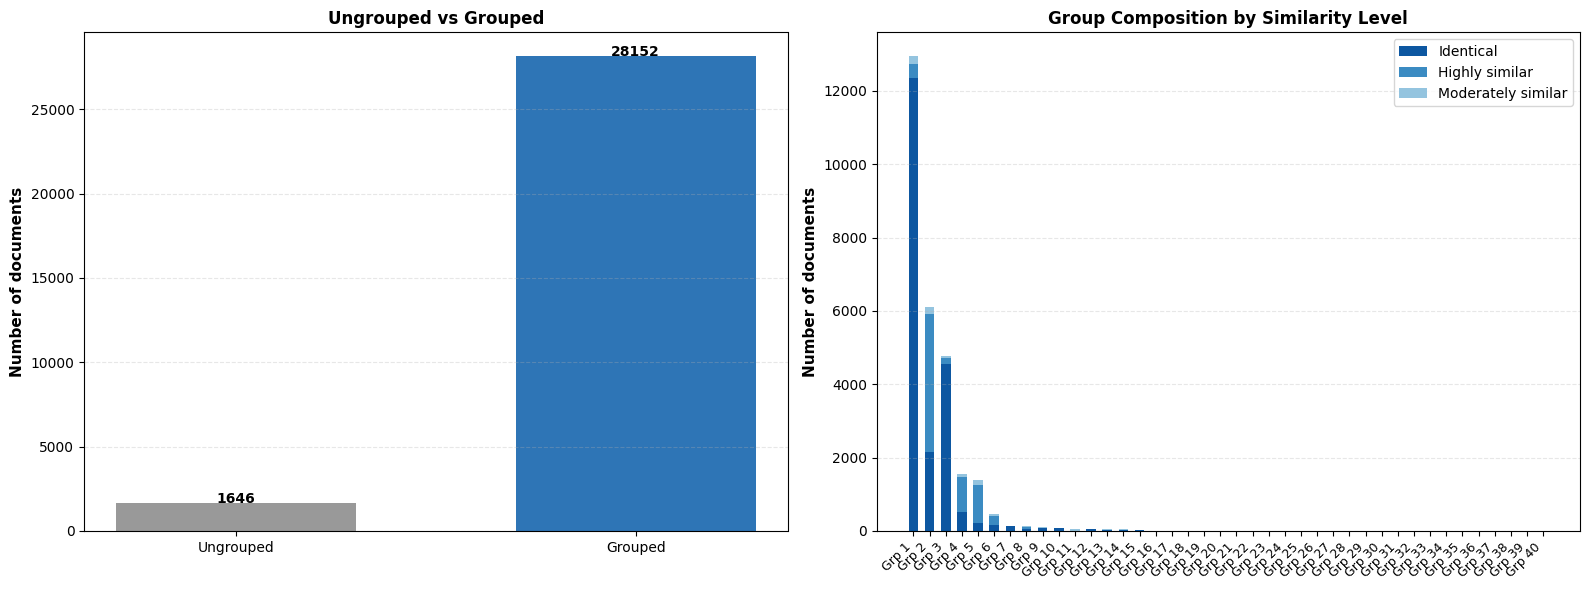

In [26]:
# Plot parameters
MIN_GROUP_SIZE_PLOT = 3
TOP_N_GROUPS = 40

# Prepare data for plotting
ungrouped = results[results['group_size'] == 1]
grouped = results[results['group_size'] > 1]

# Filter by size
large_groups = grouped[grouped['group_size'] >= MIN_GROUP_SIZE_PLOT]
large_group_ids = sorted(large_groups['group_id'].unique(),
                          key=lambda g: large_groups[large_groups['group_id'] == g].iloc[0]['group_size'],
                          reverse=True)[:TOP_N_GROUPS]

# Build plot data
plot_data = []
plot_labels = []

# Ungrouped bar
plot_labels.append('Ungrouped')
plot_data.append([len(ungrouped), 0, 0])

# Large groups
for gid in large_group_ids:
    g_data = grouped[grouped['group_id'] == gid]
    counts = g_data['group_label'].value_counts().to_dict()
    plot_labels.append(f"Grp {gid}")
    plot_data.append([
        counts.get('Grouped - Identical', 0),
        counts.get('Grouped - Highly similar', 0),
        counts.get('Grouped - Moderately similar', 0)
    ])

# Convert to arrays for stacking
plot_data = np.array(plot_data).T

# Create figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Colors - three shades of blue for the right plot
blue_colors = [plt.cm.Blues(0.85), plt.cm.Blues(0.65), plt.cm.Blues(0.4)]  # Dark, medium, light blue
bar_width = 0.6

# --- SUBPLOT 1: Ungrouped vs Grouped Summary ---
summary_labels = ['Ungrouped', 'Grouped']
summary_counts = [len(ungrouped), len(grouped)]
summary_colors = ['#999999', '#2E75B6']

ax1.bar(summary_labels, summary_counts, color=summary_colors, width=bar_width)
ax1.set_ylabel('Number of documents', fontsize=11, fontweight='bold')
ax1.set_title('Ungrouped vs Grouped', fontsize=12, fontweight='bold')
ax1.grid(axis='y', alpha=0.3, linestyle='--')
for i, v in enumerate(summary_counts):
    ax1.text(i, v + 10, str(v), ha='center', fontweight='bold')

# --- SUBPLOT 2: Group Composition (stacked bars) ---
group_plot_labels = plot_labels[1:]
group_plot_data = [row[1:] for row in plot_data]
x_pos = np.arange(len(group_plot_labels))

bottom = np.zeros(len(group_plot_labels))
labels_stack = ['Identical', 'Highly similar', 'Moderately similar']

for i, (row, label, color) in enumerate(zip(group_plot_data, labels_stack, blue_colors)):
    ax2.bar(x_pos, row, bar_width, label=label, bottom=bottom, color=color)
    bottom += np.array(row)

ax2.set_ylabel('Number of documents', fontsize=11, fontweight='bold')
#ax2.set_xlabel('Group (sorted by size)', fontsize=11, fontweight='bold')
ax2.set_title('Group Composition by Similarity Level', fontsize=12, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(group_plot_labels, rotation=45, ha='right', fontsize=9)
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()

# Save
plot_filename = f"{Path(filepath).stem}_grouped_plot.png"
plt.savefig(plot_filename, dpi=100, bbox_inches='tight')
print(f"✓ Saved plot: {Path(plot_filename).absolute()}")
if IN_COLAB:
    files.download(plot_filename)

plt.show()


## Log-scale y-axis

✓ Saved plot: /content/noaa_narw_2026_grouped_ylog_plot.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

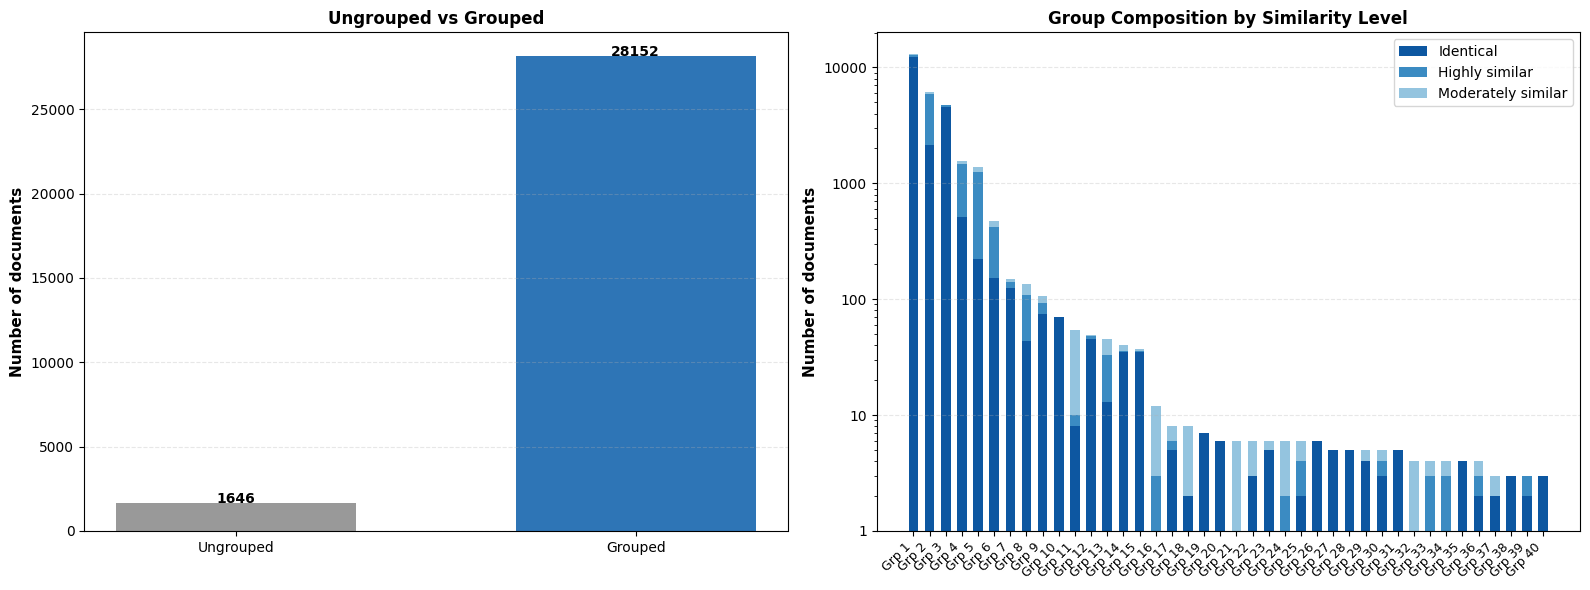

In [27]:
# Plot parameters
MIN_GROUP_SIZE_PLOT = 3
TOP_N_GROUPS = 40

# Prepare data for plotting
ungrouped = results[results['group_size'] == 1]
grouped = results[results['group_size'] > 1]

# Filter by size
large_groups = grouped[grouped['group_size'] >= MIN_GROUP_SIZE_PLOT]
large_group_ids = sorted(large_groups['group_id'].unique(),
                          key=lambda g: large_groups[large_groups['group_id'] == g].iloc[0]['group_size'],
                          reverse=True)[:TOP_N_GROUPS]

# Build plot data
plot_data = []
plot_labels = []

# Ungrouped bar
plot_labels.append('Ungrouped')
plot_data.append([len(ungrouped), 0, 0])

# Large groups
for gid in large_group_ids:
    g_data = grouped[grouped['group_id'] == gid]
    counts = g_data['group_label'].value_counts().to_dict()
    plot_labels.append(f"Grp {gid}")
    plot_data.append([
        counts.get('Grouped - Identical', 0),
        counts.get('Grouped - Highly similar', 0),
        counts.get('Grouped - Moderately similar', 0)
    ])

# Convert to arrays for stacking
plot_data = np.array(plot_data).T

# Create figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Colors - three shades of blue for the right plot
blue_colors = [plt.cm.Blues(0.85), plt.cm.Blues(0.65), plt.cm.Blues(0.4)]  # Dark, medium, light blue
bar_width = 0.6

# --- SUBPLOT 1: Ungrouped vs Grouped Summary ---
summary_labels = ['Ungrouped', 'Grouped']
summary_counts = [len(ungrouped), len(grouped)]
summary_colors = ['#999999', '#2E75B6']

ax1.bar(summary_labels, summary_counts, color=summary_colors, width=bar_width)
ax1.set_ylabel('Number of documents', fontsize=11, fontweight='bold')
ax1.set_title('Ungrouped vs Grouped', fontsize=12, fontweight='bold')
ax1.grid(axis='y', alpha=0.3, linestyle='--')
for i, v in enumerate(summary_counts):
    ax1.text(i, v + 10, str(v), ha='center', fontweight='bold')

# --- SUBPLOT 2: Group Composition (stacked bars) ---
group_plot_labels = plot_labels[1:]
group_plot_data = [row[1:] for row in plot_data]
x_pos = np.arange(len(group_plot_labels))

bottom = np.zeros(len(group_plot_labels))
labels_stack = ['Identical', 'Highly similar', 'Moderately similar']

for i, (row, label, color) in enumerate(zip(group_plot_data, labels_stack, blue_colors)):
    ax2.bar(x_pos, row, bar_width, label=label, bottom=bottom, color=color)
    bottom += np.array(row)

ax2.set_ylabel('Number of documents', fontsize=11, fontweight='bold')
#ax2.set_xlabel('Group (sorted by size)', fontsize=11, fontweight='bold')
ax2.set_title('Group Composition by Similarity Level', fontsize=12, fontweight='bold')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(group_plot_labels, rotation=45, ha='right', fontsize=9)
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.set_yscale('log')
ax2.set_yticks([1, 10, 100, 1000, 10000])
ax2.set_yticklabels(['1', '10', '100', '1000', '10000'])

plt.tight_layout()

# Save
plot_filename = f"{Path(filepath).stem}_grouped_ylog_plot.png"
plt.savefig(plot_filename, dpi=100, bbox_inches='tight')
print(f"✓ Saved plot: {Path(plot_filename).absolute()}")
if IN_COLAB:
    files.download(plot_filename)

plt.show()


## Family plot

Each bar is a family, stacked by its member groups. Use it to see whether a family is on large group or several smaller ones.

✓ Saved family plot: /content/noaa_narw_2026_family_plot.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

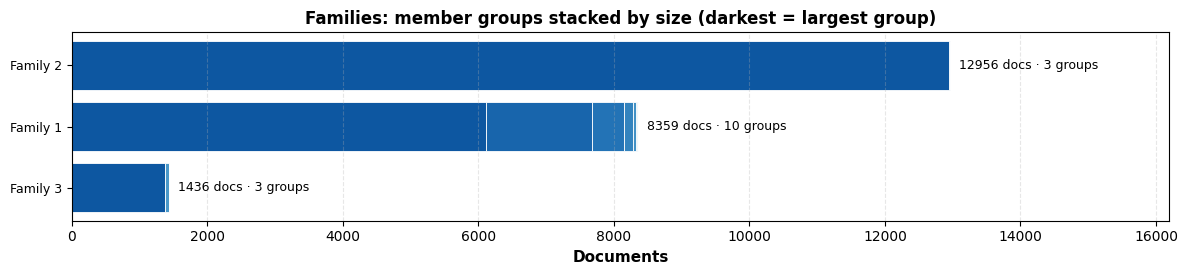

In [28]:
TOP_N_FAMILIES = 25

fam_rows = results[results['family_id'].notna()]
fam_summary = fam_rows.groupby('family_id').agg(docs=('group_id', 'size'), groups=('group_id', 'nunique'))
fam_summary = fam_summary[fam_summary['groups'] > 1].sort_values('docs', ascending=False).head(TOP_N_FAMILIES)

if len(fam_summary) == 0:
    print("⊘ No families spanning 2+ groups to plot")
else:
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(fam_summary) + 1.5))
    ypos = np.arange(len(fam_summary))[::-1]
    max_docs = fam_summary['docs'].max()

    for y, fid in zip(ypos, fam_summary.index):
        sizes = fam_rows[fam_rows['family_id'] == fid]['group_id'].value_counts()
        shades = plt.cm.Blues(np.linspace(0.85, 0.35, len(sizes)))
        left = 0
        for shade, n in zip(shades, sizes.values):
            ax.barh(y, n, left=left, color=shade, edgecolor='white', linewidth=0.6)
            left += n
        ax.text(left + max_docs * 0.01, y, f"{left} docs · {len(sizes)} groups", va='center', fontsize=9)

    ax.set_yticks(ypos)
    ax.set_yticklabels([f"Family {fid}" for fid in fam_summary.index], fontsize=9)
    ax.set_xlabel('Documents', fontsize=11, fontweight='bold')
    ax.set_title('Families: member groups stacked by size (darkest = largest group)', fontsize=12, fontweight='bold')
    ax.set_xlim(0, max_docs * 1.25)
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    plt.tight_layout()

    family_plot_filename = f"{Path(filepath).stem}_family_plot.png"
    plt.savefig(family_plot_filename, dpi=100, bbox_inches='tight')
    print(f"✓ Saved family plot: {Path(family_plot_filename).absolute()}")
    if IN_COLAB:
        files.download(family_plot_filename)
    plt.show()


## Family composition
Shows which groups make up each family, stacked by similarity level on a log scale, and saves a table of the same breakdown.

,family_id,group_id,family_anchor_group,comments,identical,highly_similar,moderately_similar
0,2,1,True,12952,12367,366,219
1,2,49,False,2,2,0,0
2,2,56,False,2,2,0,0
3,1,2,False,6117,2161,3754,202
4,1,4,True,1562,510,965,87
5,1,6,False,474,152,265,57
6,1,8,False,134,44,65,25
7,1,13,False,45,13,20,12
8,1,16,False,12,0,3,9
9,1,18,False,8,2,0,6


✓ Saved family table: /content/noaa_narw_2026_family_composition.csv
✓ Saved family composition plot: /content/noaa_narw_2026_family_composition_plot.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

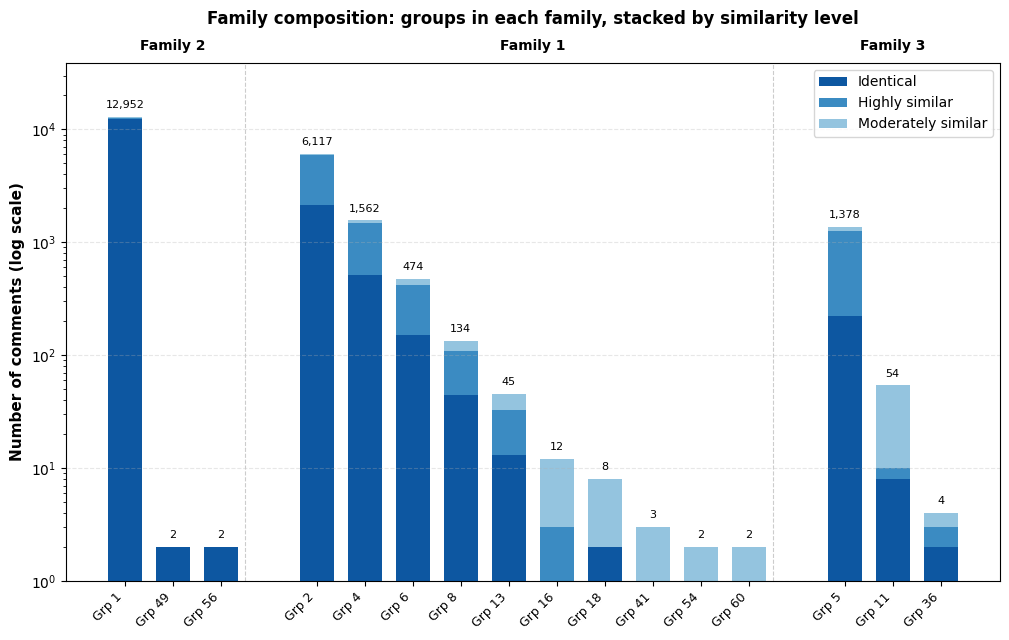

In [29]:
# Family composition: each family's groups side by side, stacked by similarity level
LEVELS = ['Grouped - Identical', 'Grouped - Highly similar', 'Grouped - Moderately similar']
LEVEL_NAMES = ['Identical', 'Highly similar', 'Moderately similar']
LEVEL_COLORS = [plt.cm.Blues(0.85), plt.cm.Blues(0.65), plt.cm.Blues(0.4)]
FAMILY_GAP = 1.0  # space between families on the x-axis

fam_rows = results[results['family_id'].notna()]

if len(fam_rows) == 0:
    print("⊘ No families to plot")
else:
    fam_order = fam_rows.groupby('family_id').size().sort_values(ascending=False).index.tolist()

    table_rows, bars, fam_spans = [], [], []
    x = 0.0
    for fid in fam_order:
        fam = fam_rows[fam_rows['family_id'] == fid]
        anchor_group = results.at[int(fam['family_anchor_row'].iloc[0]), 'group_id']
        group_order = fam.groupby('group_id')['group_size'].first().sort_values(ascending=False).index
        start = x
        for gid in group_order:
            g = fam[fam['group_id'] == gid]
            counts = g['group_label'].value_counts()
            level_counts = [int(counts.get(level, 0)) for level in LEVELS]
            total = int(len(g))
            bars.append((x, gid, level_counts, total))
            table_rows.append({
                'family_id': int(fid),
                'group_id': int(gid),
                'family_anchor_group': bool(gid == anchor_group),
                'comments': total,
                'identical': level_counts[0],
                'highly_similar': level_counts[1],
                'moderately_similar': level_counts[2],
            })
            x += 1
        fam_spans.append((fid, start, x - 1))
        x += FAMILY_GAP

    fig_w = max(10, 0.45 * len(bars) + 3)
    fig, ax = plt.subplots(figsize=(fig_w, 6.5))
    xs = np.array([b[0] for b in bars])
    bottom = np.zeros(len(bars))
    for k, (name, color) in enumerate(zip(LEVEL_NAMES, LEVEL_COLORS)):
        vals = np.array([b[2][k] for b in bars], dtype=float)
        mask = vals > 0
        ax.bar(xs[mask], vals[mask], 0.7, bottom=bottom[mask], color=color, label=name)
        bottom += vals

    for xp, gid, _, total in bars:
        ax.text(xp, total * 1.15, f"{total:,}", ha='center', va='bottom', fontsize=8)

    for fid, s, e in fam_spans:
        ax.text((s + e) / 2, 1.02, f"Family {fid}", transform=ax.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=10, fontweight='bold')
    for _, _, e in fam_spans[:-1]:
        ax.axvline(e + FAMILY_GAP / 2, color='#cccccc', linestyle='--', linewidth=0.8)

    ax.set_yscale('log')
    ax.set_ylim(1, bottom.max() * 3)
    ax.set_ylabel('Number of comments (log scale)', fontsize=11, fontweight='bold')
    ax.set_xticks(xs)
    ax.set_xticklabels([f"Grp {b[1]}" for b in bars], rotation=45, ha='right', fontsize=9)
    ax.set_title('Family composition: groups in each family, stacked by similarity level',
                 fontsize=12, fontweight='bold', pad=28)
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    plt.tight_layout()

    family_table = pd.DataFrame(table_rows)
    display(family_table)

    table_filename = f"{Path(filepath).stem}_family_composition.csv"
    family_table.to_csv(table_filename, index=False)
    print(f"✓ Saved family table: {Path(table_filename).absolute()}")

    plot_filename = f"{Path(filepath).stem}_family_composition_plot.png"
    plt.savefig(plot_filename, dpi=100, bbox_inches='tight')
    print(f"✓ Saved family composition plot: {Path(plot_filename).absolute()}")
    if IN_COLAB:
        files.download(table_filename)
        files.download(plot_filename)
    plt.show()

# Interactive Explorer

Tool that lets you browse the groups of similar comments, select any two to compare side-by-side, and see their differences highlighted with a similarity score. Use to verify that the grouping makes sense before downloading the results.

## Import processed data

Run setup, functions first.

In [ ]:
label_order = ['Ungrouped', 'Grouped - Identical', 'Grouped - Highly similar', 'Grouped - Moderately similar']

if IN_COLAB:
    print("Click 'Choose Files' to upload your *_grouped.csv file:")
    uploaded = files.upload()
    grouped_path = list(uploaded.keys())[0]
else:
    grouped_path = input("Enter path to your grouped CSV: ")

results = pd.read_csv(grouped_path, dtype=str, keep_default_na=False)
for col in ['group_id', 'group_size', 'best_match_id', 'group_rep_id']:
    results[col] = results[col].astype(int)
for col in ['family_id', 'family_size', 'family_anchor_row']:
    results[col] = pd.to_numeric(results[col].replace('', np.nan)).astype('Int64')
for col in ['J_to_rep', 'max_j_in_group']:
    results[col] = results[col].astype(float)
for col in ['is_identical', 'is_group_rep']:
    results[col] = results[col].map({'True': True, 'False': False})
results['group_label'] = pd.Categorical(results['group_label'], categories=label_order, ordered=True)

comment_col = detect_comment_column(results)
id_col = detect_id_column(results)
family_center_doc = results['family_anchor_row'].values
normalized_texts = np.array(
    [normalize_text(t) for t in tqdm(results[comment_col], desc='Normalizing', unit='doc')],
    dtype=object
)

print(f"Loaded {len(results):,} rows")

In [ ]:
bad = results[(results['group_size'] > 1) & (results['group_label'] == 'Ungrouped')]
print(len(bad))
print(bad[['group_id', 'group_size', 'J_to_rep', 'max_j_in_group', 'is_identical']])


## Compare families

Browse families that span 2+ groups and compare any two group representatives in the family.


### Explorer functions

In [30]:
def get_jaccard_similarity(norm_text1, norm_text2, k=5):
    """Jaccard similarity on k-word shingles (assumes already-normalized text).

    Args:
        norm_text1, norm_text2: already normalized text (whitespace-separated words)
        k: shingle size in words

    Returns:
        Jaccard similarity in [0, 1]
    """
    words1 = norm_text1.split()
    words2 = norm_text2.split()

    # For documents with < k words, use whole text as one shingle (consistent with build_shingle_matrix)
    if len(words1) < k:
        shingles1 = {' '.join(words1)} if words1 else {''}
    else:
        shingles1 = {' '.join(words1[i:i+k]) for i in range(len(words1) - k + 1)}

    if len(words2) < k:
        shingles2 = {' '.join(words2)} if words2 else {''}
    else:
        shingles2 = {' '.join(words2[i:i+k]) for i in range(len(words2) - k + 1)}

    intersection = len(shingles1 & shingles2)
    union = len(shingles1 | shingles2)
    return intersection / union if union > 0 else 0.0


In [31]:
BUCKET_LABELS = {
    'near_exact': 'Near-Exact (J > 0.95)',
    'high_var': 'High Similarity (0.80 - 0.95)',
    'med_var': 'Medium Similarity (0.60 - 0.80)',
    'low_var': 'Low Similarity (J < 0.60)',
    'all': 'All Documents'
}

def get_bucket_label(bucket_name):
    """Get descriptive label for bucket."""
    return BUCKET_LABELS.get(bucket_name, bucket_name)

def compare_docs_side_by_side(doc1_text, doc2_text):
    """Word-level diff and Jaccard similarity."""
    words1 = str(doc1_text).split()
    words2 = str(doc2_text).split()

    matcher = SequenceMatcher(None, words1, words2)
    word_sim = matcher.ratio()
    jaccard_sim = get_jaccard_similarity(normalize_text(str(doc1_text)), normalize_text(str(doc2_text)), k=5)

    left_html = right_html = ''
    for tag, i1, i2, j1, j2 in matcher.get_opcodes():
        if tag == 'equal':
            left_html += ' '.join(words1[i1:i2]) + ' '
            right_html += ' '.join(words2[j1:j2]) + ' '
        elif tag == 'delete':
            left_html += f'<span style="background: #ffcccc; text-decoration: line-through;">{" ".join(words1[i1:i2])}</span> '
        elif tag == 'insert':
            right_html += f'<span style="background: #ccffcc;">{" ".join(words2[j1:j2])}</span> '
        elif tag == 'replace':
            left_html += f'<span style="background: #ffcccc;">{" ".join(words1[i1:i2])}</span> '
            right_html += f'<span style="background: #ccffcc;">{" ".join(words2[j1:j2])}</span> '

    return jaccard_sim, word_sim, left_html, right_html

def build_explorer(results, comment_col, id_col):
    """Simplified explorer: groups sorted by J_to_rep."""
    # Filter to multi-member groups
    multi_groups = results.groupby('group_id').filter(lambda x: len(x) > 1)

    if len(multi_groups) == 0:
        print("⊘ No groups with 2+ members to explore")
        return

    # Build group list (sorted by size, descending)
    group_ids = multi_groups['group_id'].unique()
    group_options = {
        f"Group {int(gid)} · {(multi_groups['group_id'] == gid).sum()} copies": gid
        for gid in sorted(group_ids, key=lambda g: (multi_groups['group_id'] == g).sum(), reverse=True)
    }

    group_dropdown = Dropdown(
        options=group_options,
        value=list(group_options.values())[0],
        description='Group:',
        layout={'width': '600px'}
    )

    doc_idx_1 = IntText(value=0, description='Doc 1:', min=0, max=1000, layout={'width': '250px'})
    doc_idx_2 = IntText(value=1, description='Doc 2:', min=0, max=1000, layout={'width': '250px'})

    output_area = Output()

    def update_group(change):
        """Update doc list when group changes (sorted by J desc)."""
        group_id = change['new']
        group_rows = multi_groups[multi_groups['group_id'] == group_id].sort_values('J_to_rep', ascending=False)

        max_idx = len(group_rows) - 1
        doc_idx_1.max = max_idx
        doc_idx_2.max = max_idx
        doc_idx_1.value = 0
        doc_idx_2.value = min(1, max_idx)

        explore(group_id, 0, 1, group_rows)

    def explore(group_id, d1_idx, d2_idx, group_rows):
        """Display two docs side-by-side."""
        with output_area:
            clear_output(wait=True)

            group_rows_sorted = group_rows.sort_values('J_to_rep', ascending=False)

            if len(group_rows_sorted) < 2:
                display(HTML("<p style='color: orange;'>⊘ Not enough documents to compare</p>"))
                return

            d1_idx = min(max(d1_idx, 0), len(group_rows_sorted) - 1)
            d2_idx = min(max(d2_idx, 0), len(group_rows_sorted) - 1)

            if d1_idx == d2_idx:
                d2_idx = (d1_idx + 1) % len(group_rows_sorted)

            row1 = group_rows_sorted.iloc[d1_idx]
            row2 = group_rows_sorted.iloc[d2_idx]

            jaccard_sim, word_sim, left_html, right_html = compare_docs_side_by_side(
                row1[comment_col],
                row2[comment_col]
            )

            id1 = row1[id_col] if id_col else f"Doc {d1_idx}"
            id2 = row2[id_col] if id_col else f"Doc {d2_idx}"

            html = f"""
            <div style='font-family: sans-serif; font-size: 13px;'>
            <h4>Group {int(group_id)} (sorted by J to representative)</h4>

            <p style='margin: 8px 0; color: #666;'>
                <b>Jaccard:</b> <span style='color: #2E86AB; font-weight: bold;'>{jaccard_sim:.1%}</span>·
                <b>Word-level:</b> <span style='color: #2E86AB; font-weight: bold;'>{word_sim:.1%}</span>
            </p>

            <p style='margin: 4px 0; color: #666; font-size: 12px;'>
                Doc {d1_idx + 1} of {len(group_rows_sorted)} vs Doc {d2_idx + 1} of {len(group_rows_sorted)}
            </p>

            <hr style='margin: 8px 0; border: none; border-top: 1px solid #ddd;'>

            <table style='width: 100%; border-collapse: collapse; font-size: 12px;'>
            <tr style='background: #f0f0f0;'>
                <th style='text-align: left; padding: 6px; border: 1px solid #ccc;'>{id1}</th>
                <th style='text-align: left; padding: 6px; border: 1px solid #ccc;'>{id2}</th>
            </tr>
            <tr>
                <td style='padding: 8px; border: 1px solid #ddd; background: #fafafa; word-wrap: break-word; line-height: 1.5; max-height: 300px; overflow-y: auto;'>{left_html}</td>
                <td style='padding: 8px; border: 1px solid #ddd; background: #fafafa; word-wrap: break-word; line-height: 1.5; max-height: 300px; overflow-y: auto;'>{right_html}</td>
            </tr>
            </table>
            </div>
            """
            display(HTML(html))

    def on_group_change(change):
        update_group(change)

    def on_doc_idx_change(change):
        group_id = group_dropdown.value
        group_rows = multi_groups[multi_groups['group_id'] == group_id]
        explore(group_id, doc_idx_1.value, doc_idx_2.value, group_rows)

    group_dropdown.observe(on_group_change, names='value')
    doc_idx_1.observe(on_doc_idx_change, names='value')
    doc_idx_2.observe(on_doc_idx_change, names='value')

    display(VBox([
        HTML("<h3>Interactive Explorer: Groups & Comparisons</h3>"),
        HTML(f"<p style='font-size: 0.9em; color: #666;'>{len(group_ids)} groups with 2+ documents</p>"),
        group_dropdown,
        HBox([doc_idx_1, doc_idx_2]),
    ]))
    display(output_area)

    # Initialize first group
    group_id = group_dropdown.value
    group_rows = multi_groups[multi_groups['group_id'] == group_id].sort_values('J_to_rep', ascending=False)
    explore(group_id, 0, 1, group_rows)

In [32]:
# family explorer
def family_members(family_rows, fid, family_center_doc, normalized_texts):
    rows = family_rows[family_rows['family_id'] == fid]
    anchor = family_center_doc[rows.index[0]]
    reps = rows[rows['is_group_rep']]
    scored = sorted(
        ((get_jaccard_similarity(normalized_texts[doc], normalized_texts[anchor]), doc, row)
         for doc, row in reps.iterrows() if doc != anchor),
        key=lambda t: -t[0]
    )
    options = {
        f"Group {int(row['group_id'])} · {int(row['group_size'])} copies · J to anchor {j:.0%}": doc
        for j, doc, row in scored
    }
    return anchor, options

def family_pair_html(results, comment_col, id_col, normalized_texts, a, b):
    _, word_sim, left_html, right_html = compare_docs_side_by_side(
        results.at[a, comment_col], results.at[b, comment_col]
    )
    jac = get_jaccard_similarity(normalized_texts[a], normalized_texts[b])
    label_a = results.at[a, id_col] if id_col else f"Row {a + 1}"
    label_b = results.at[b, id_col] if id_col else f"Row {b + 1}"
    return f"""
    <div style='font-family: sans-serif; font-size: 13px;'>
    <p style='margin: 8px 0; color: #666;'>
        <b>Jaccard (normalized):</b> <span style='color: #2E86AB; font-weight: bold;'>{jac:.1%}</span> ·
        <b>Word-level:</b> <span style='color: #2E86AB; font-weight: bold;'>{word_sim:.1%}</span>
    </p>
    <table style='width: 100%; border-collapse: collapse; font-size: 12px;'>
    <tr style='background: #f0f0f0;'>
        <th style='text-align: left; padding: 6px; border: 1px solid #ccc;'>Anchor · Group {int(results.at[a, 'group_id'])} · {label_a}</th>
        <th style='text-align: left; padding: 6px; border: 1px solid #ccc;'>Group {int(results.at[b, 'group_id'])} · {label_b}</th>
    </tr>
    <tr>
        <td style='padding: 8px; border: 1px solid #ddd; background: #fafafa; word-wrap: break-word; line-height: 1.5;'>{left_html}</td>
        <td style='padding: 8px; border: 1px solid #ddd; background: #fafafa; word-wrap: break-word; line-height: 1.5;'>{right_html}</td>
    </tr>
    </table>
    </div>
    """

def build_family_explorer(results, comment_col, id_col, family_center_doc, normalized_texts):
    family_rows = results[results['family_id'].notna()]
    fam_info = family_rows.groupby('family_id').agg(docs=('group_id', 'size'), groups=('group_id', 'nunique'))
    fam_info = fam_info[fam_info['groups'] > 1].sort_values('docs', ascending=False)

    if len(fam_info) == 0:
        print("⊘ No families spanning 2+ groups to explore")
        return

    fam_dropdown = Dropdown(
        options={f"Family {fid} · {r.groups} groups · {r.docs} docs": fid for fid, r in fam_info.iterrows()},
        description='Family:',
        layout={'width': '600px'}
    )
    anchor_html = HTML()
    compare_dropdown = Dropdown(description='Compare with:', layout={'width': '600px'})
    fam_output = Output()
    state = {'busy': False, 'anchor': None}

    def refresh(change=None):
        if state['busy'] or state['anchor'] is None or compare_dropdown.value is None:
            return
        with fam_output:
            clear_output(wait=True)
            display(HTML(family_pair_html(results, comment_col, id_col, normalized_texts,
                                          state['anchor'], compare_dropdown.value)))

    def on_family(change):
        state['busy'] = True
        anchor, options = family_members(family_rows, change['new'], family_center_doc, normalized_texts)
        state['anchor'] = anchor
        anchor_row = results.loc[anchor]
        anchor_html.value = (
            f"<p style='font-size: 13px;'><b>Pinned anchor:</b> Group {int(anchor_row['group_id'])} · "
            f"{int(anchor_row['group_size'])} copies</p>"
        )
        compare_dropdown.options = options
        compare_dropdown.value = next(iter(options.values()), None)
        state['busy'] = False
        refresh()

    fam_dropdown.observe(on_family, names='value')
    compare_dropdown.observe(refresh, names='value')

    display(VBox([
        HTML("<h3>Family Explorer</h3>"),
        HTML("<p style='font-size: 0.9em; color: #666;'>The family anchor is pinned on the left. "
             "Pick any other group to compare it against; groups are listed by similarity to the anchor.</p>"),
        fam_dropdown,
        anchor_html,
        compare_dropdown,
    ]))
    display(fam_output)
    on_family({'new': fam_dropdown.value})


### Family explorer

In [33]:
build_family_explorer(results, comment_col, id_col, family_center_doc, normalized_texts)

Output()

### Group explorer

In [34]:
build_explorer(results, comment_col, id_col)

Output()